In [ ]:
# `import smlm` 需要 Py_Smile 在 sys.path 上; notebook 放进子目录后自己找一下
import pathlib
import sys

for _q in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_q / 'smlm' / '__init__.py').is_file():
        sys.path.insert(0, str(_q))
        break


In [1]:
%load_ext autoreload
%autoreload 2

## Load Raw

In [2]:
from smlm.io import load_raw
from smlm import viz

# EMCCD 的 SIF —— em_gain 自动从头信息读出
src = r"G:\SPARK\20261124\SPARK Cy3_avidin_532nm_6mW_0p1S_2000frames_fov3.sif"


In [3]:
# sif
raw = load_raw(src)
print(raw.data.shape, raw.n_frames, raw.em_gain, raw.exposure_time)
pixel_size=106.6 # nm/pixel

(2000, 512, 512) 2000 300.0 0.1


In [ ]:
# 保存图像为 tif(与源文件同目录同名, 加 _photons 后缀)
import os
from smlm.io import save_tif
dst = os.path.splitext(src)[0] + "_raw.tif"
save_tif(raw.data, dst)

In [4]:
# 接下来交给 camera 层转光子
from smlm.camera import EMCCD
cam = EMCCD(conv_factor=5.75, em_gain=300)
image = cam.process(raw, pixel_size=106.6)

In [ ]:
# tif
raw = load_raw(src)
print(raw.data.shape, raw.em_gain)   # em_gain 为 None
raw.exposure_time=0.1
pixel_size=106.6 # nm/pixel

In [ ]:
# 接下来交给 camera 层转光子
from smlm.camera import sCMOS
import numpy as np
H, W = raw.data.shape[1:]            # 视场尺寸 (H, W)
gain_map   = np.full((H, W), 33.448)      # 常数增益图
offset_map = np.full((H, W), 1894)    # 常数暗电平图
cam = sCMOS(gain_map=gain_map,offset_map=offset_map)
image = cam.process(raw, pixel_size=106.6)

## Preprocessing

In [5]:
from smlm.imgprocess import Pipeline, Crop, SelectFrames
# 预处理: 使用完整 TIF 视场与全部 10000 帧
prep = Pipeline(Crop(y=(0, 512), x=(0,512)),
                SelectFrames(start=None,stop=None))
stack = prep(image)
stack.shape

(2000, 512, 512)

<Axes: title={'center': 'frame 1'}, xlabel='x (px)', ylabel='y (px)'>

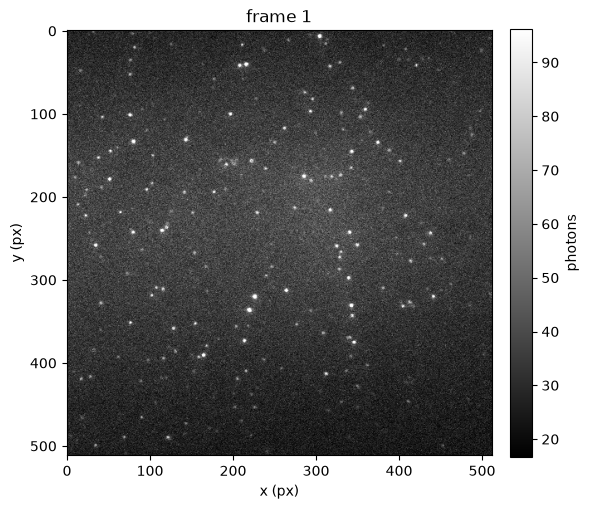

In [6]:
from smlm.viz import show_frames
show_frames(stack, frames=1)

## Localization settings

processing frame 50 / 2000
processing frame 100 / 2000
processing frame 150 / 2000
processing frame 200 / 2000
processing frame 250 / 2000
processing frame 300 / 2000
processing frame 350 / 2000
processing frame 400 / 2000
processing frame 450 / 2000
processing frame 500 / 2000
processing frame 550 / 2000
processing frame 600 / 2000
processing frame 650 / 2000
processing frame 700 / 2000
processing frame 750 / 2000
processing frame 800 / 2000
processing frame 850 / 2000
processing frame 900 / 2000
processing frame 950 / 2000
processing frame 1000 / 2000
processing frame 1050 / 2000
processing frame 1100 / 2000
processing frame 1150 / 2000
processing frame 1200 / 2000
processing frame 1250 / 2000
processing frame 1300 / 2000
processing frame 1350 / 2000
processing frame 1400 / 2000
processing frame 1450 / 2000
processing frame 1500 / 2000
processing frame 1550 / 2000
processing frame 1600 / 2000
processing frame 1650 / 2000
processing frame 1700 / 2000
processing frame 1750 / 2000
proce

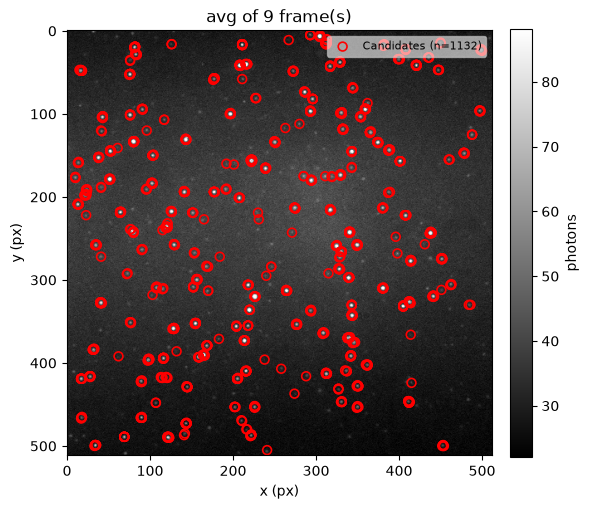

In [ ]:
from smlm.io import run_cached
from smlm.localize import LocalMaxDetector
import numpy as np

# Choose one workflow: separate steps or localize_stack.
USE_LOCALIZE_STACK = False
READ_LOC_CACHE = False
CACHE_PATH = src

K_SIGMA = 2.6
DET_KW = dict(edge=5, f_em=np.sqrt(2), bg_window=15,
              max_size=7, min_neighbors=2, verbose=True)
LOC_KW = dict(edge=5, F_EM=np.sqrt(2.0), use_pixel=False,
              use_gradient=True, n_jobs=12, verbose=True)
FILTER_KW = dict(photons=(20, 1e7), bg=(0, 1e5),
                 sigma=(0.5, 5.0), lp=(0.0, 1.0))

cand = detector = localizer = None
if not USE_LOCALIZE_STACK:
    if READ_LOC_CACHE:
        locs, _ = run_cached(stack, CACHE_PATH, read_cache=True)
    else:
        detector = LocalMaxDetector(k_sigma=K_SIGMA, **DET_KW)
        cand = detector.detect(stack)

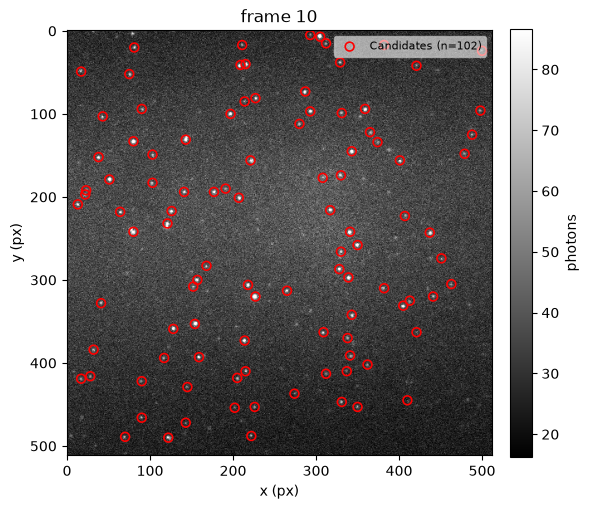

In [13]:
ax = viz.overlay_points(stack, cand, frames=[10],
                                color='r', marker='o')

## Option A: separate detect and localize

In [14]:
from smlm.localize import MLELocalizer, filter_locs
if not USE_LOCALIZE_STACK and not READ_LOC_CACHE:
    localizer = MLELocalizer(**LOC_KW)
    locs = localizer.localize(stack, cand)
    locs = filter_locs(locs, **FILTER_KW)

21000 / 21000 candidates in-range, fitting...


MLE fitting: 100%|██████████| 4616/4616 [00:00<00:00, 5313.08it/s]


MLE fitting done in 4.92s (0.23 ms/loc)
MLE done, 21000 localizations kept.
[filter] removed 92 / 21000 (0.44%), kept 20908


In [15]:
from smlm.io import save_cached_locs
if not USE_LOCALIZE_STACK and not READ_LOC_CACHE:
    save_cached_locs(
        locs, stack, CACHE_PATH,
        method={'detector': detector, 'localizer': localizer},
        filter_kw=FILTER_KW,
        compressed=False,
    )

[cache] saved 20908 locs -> G:\SPARK\20261124\SPARK Cy3_avidin_532nm_6mW_0p1S_2000frames_fov3.locs.npz


## Option B: one-call localization

In [ ]:
from smlm.localize import localize_stack
if USE_LOCALIZE_STACK:
    locs = localize_stack(
        stack,
        k_sigma=K_SIGMA,
        det_kw=DET_KW,
        loc_kw=LOC_KW,
        filt_kw=FILTER_KW,
        src_path=CACHE_PATH,
        read_cache=READ_LOC_CACHE,
        verbose=True,
        tag='localize_stack',
    )

In [ ]:
from smlm.viz import plot_distributions
plot_distributions(locs)
ax = viz.overlay_points(stack, locs, frames=range(1,100), color='r', marker='x', size=30, linewidth = 0.5, unit='pixel',pixel_size=pixel_size)

## Drift Correction

In [16]:
import numpy as np
from smlm.datatypes import DriftTrace
from smlm.drift import CloudDriftEstimator
from smlm.imgprocess import DriftCorrector

# 只使用当前 stack 帧范围内的定位，避免帧数不一致
locs_drift = locs[locs.frame < stack.n_frames]

# ===== 开关：True=估计并校正漂移；False=零漂移（不校正，但仍做裁切）=====
USE_DRIFT = True

if USE_DRIFT:
    # 1) 估计(只需要定位)
    uncertainty = np.median(locs_drift.lp)
    est = CloudDriftEstimator(frames_per_seg=10, uncertainty=uncertainty, do_stage2=True)
    drift_trace = est.estimate(locs_drift, n_frames=stack.n_frames)
    print(f"drift estimated: total {drift_trace.total_drift:.2f} px over {drift_trace.n_frames} frames")
else:
    # 零漂移轨迹：dx = dy = 0，校正时图像与定位都不平移
    drift_trace = DriftTrace.zeros(stack.n_frames, pixel_size=pixel_size)
    print(f"USE_DRIFT=False -> zero drift trace ({drift_trace.n_frames} frames, total 0.00 px)")

# 2) 校正图像 + 定位
# 裁切窗口按视场大小自动计算，每边留 5 px 漂移缓冲
_h, _w = int(stack.shape[1]), int(stack.shape[2])
_crop = (max(8, _h - 200), max(8, _w - 200))
corr = DriftCorrector(crop=_crop, edge=5)
corr_image, corr_locs, keep_idx = corr.apply(trace=drift_trace, image=stack, locs=locs_drift)
print(f"field {_h}x{_w} -> corrected crop {corr_image.data.shape[1]}x{corr_image.data.shape[2]}, "
      f"locs kept {len(corr_locs)}/{len(locs_drift)}")


=== Stage 1: first segment as reference ===
Reference seg 0 (frames 0-9): 1281 locs
  seg  1 (f10-19): 4 iters, 995 pairs
  seg  2 (f20-29): 4 iters, 706 pairs
  seg  3 (f30-39): 3 iters, 530 pairs
  seg  4 (f40-49): 2 iters, 416 pairs
  seg  5 (f50-59): 4 iters, 379 pairs
  seg  6 (f60-69): 2 iters, 329 pairs
  seg  7 (f70-79): 4 iters, 287 pairs
  seg  8 (f80-89): 0 iters, 267 pairs
  seg  9 (f90-99): 0 iters, 264 pairs
  seg 10 (f100-109): 3 iters, 200 pairs
  seg 11 (f110-119): 2 iters, 217 pairs
  seg 12 (f120-129): 1 iters, 191 pairs
  seg 13 (f130-139): 2 iters, 173 pairs
  seg 14 (f140-149): 1 iters, 176 pairs
  seg 15 (f150-159): 1 iters, 167 pairs
  seg 16 (f160-169): 3 iters, 168 pairs
  seg 17 (f170-179): 0 iters, 161 pairs
  seg 18 (f180-189): 1 iters, 148 pairs
  seg 19 (f190-199): 2 iters, 138 pairs
  seg 20 (f200-209): 1 iters, 129 pairs
  seg 21 (f210-219): 2 iters, 117 pairs
  seg 22 (f220-229): 1 iters, 106 pairs
  seg 23 (f230-239): 2 iters, 107 pairs
  seg 24 (f240

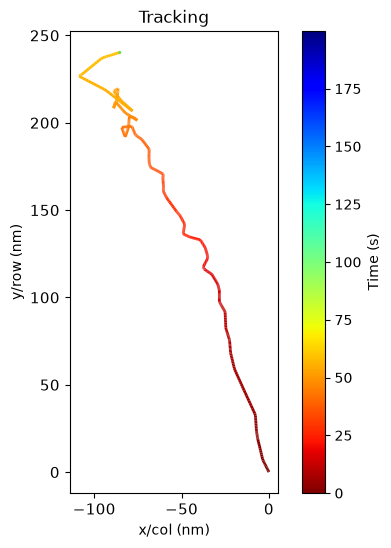

In [17]:
from smlm.viz import plot_drift
fig, ax = plot_drift(drift_trace, ex_time=raw.exposure_time,unit='nm',pixel_size=pixel_size) 


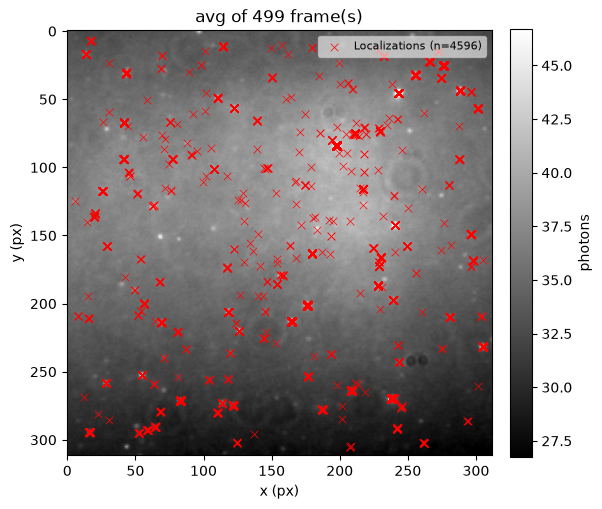

In [18]:
ax = viz.overlay_points(corr_image, corr_locs, frames=np.arange(1,500), color='r', marker='x', size=30, linewidth = 0.5)

In [ ]:
from smlm.io import save_movie, save_tif
import os

# 保存到"原 sif 文件所在目录", 文件名以 sif 名为前缀, 便于和源数据放一起
out_dir = os.path.dirname(src)
tag = os.path.splitext(os.path.basename(src))[0]
print("输出目录:", out_dir)

# 保存校正后的图像为 tif (含像素尺寸标签, 便于下游读回)
save_tif(corr_image, os.path.join(out_dir, f"{tag}_corrected.tif"))

# ① 只要图像, 原速播放 (fps = 1/exposure_time)
save_movie(corr_image, os.path.join(out_dir, f"{tag}_corrected_1x.mp4"),
           exposure_time=raw.exposure_time, frames=slice(0, 500))

# ③ 图像 + 逐帧定位点叠加
save_movie(corr_image, os.path.join(out_dir, f"{tag}_overlay_1x.mp4"), frames=slice(0, 500),
           exposure_time=raw.exposure_time, speed=1, overlay=corr_locs,
           overlay_kw=dict(c='lime', marker='x', s=18, linewidths=0.5))


## Emitter Analysis

In [19]:
from smlm.emitter import analyze_emitters_sm

# 首次出现帧窗口按当前数据集自适应（原来硬编码 (0, 9900) 只适用于 10000 帧的 fov14）
#_ffr = (0, int(stack.n_frames) - 1)
#print(f"first_frame_range = {_ffr}  (n_frames={stack.n_frames})")

emitters, emitters_raw = analyze_emitters_sm(
    corr_locs, n_frames=None,
    search_radius=0.6,
    max_gap=1000,
    min_frames=5,
    ecc_p=1e-3,
    first_frame_range=(0,50),
    motion='static', do_merge=True
)

连接得到 815 个 emitter
合并后剩余 700 / 815 个 emitter
MinDurationFilter: 保留 143 / 700
FirstFrameFilter: 保留 78 / 143
EccentricityFilter: 保留 71 / 78


In [20]:
from smlm.emitter import collect_statistics
stats = collect_statistics(emitters, locs, raw.exposure_time, 0)


(<Figure size 1100x700 with 6 Axes>,
 array([<Axes: title={'center': 'Survival time'}, xlabel='Survival time (s)', ylabel='count'>,
        <Axes: title={'center': 'Locs per emitter'}, xlabel='Locs per emitter (count)', ylabel='count'>,
        <Axes: title={'center': 'Duty cycle'}, xlabel='Duty cycle', ylabel='count'>,
        <Axes: title={'center': 'Total photons'}, xlabel='Total photons (photons)', ylabel='count'>,
        <Axes: title={'center': 'Eccentricity'}, xlabel='Eccentricity', ylabel='count'>,
        <Axes: title={'center': 'Mean PSF width'}, xlabel='Mean PSF width (pixel)', ylabel='count'>],
       dtype=object))

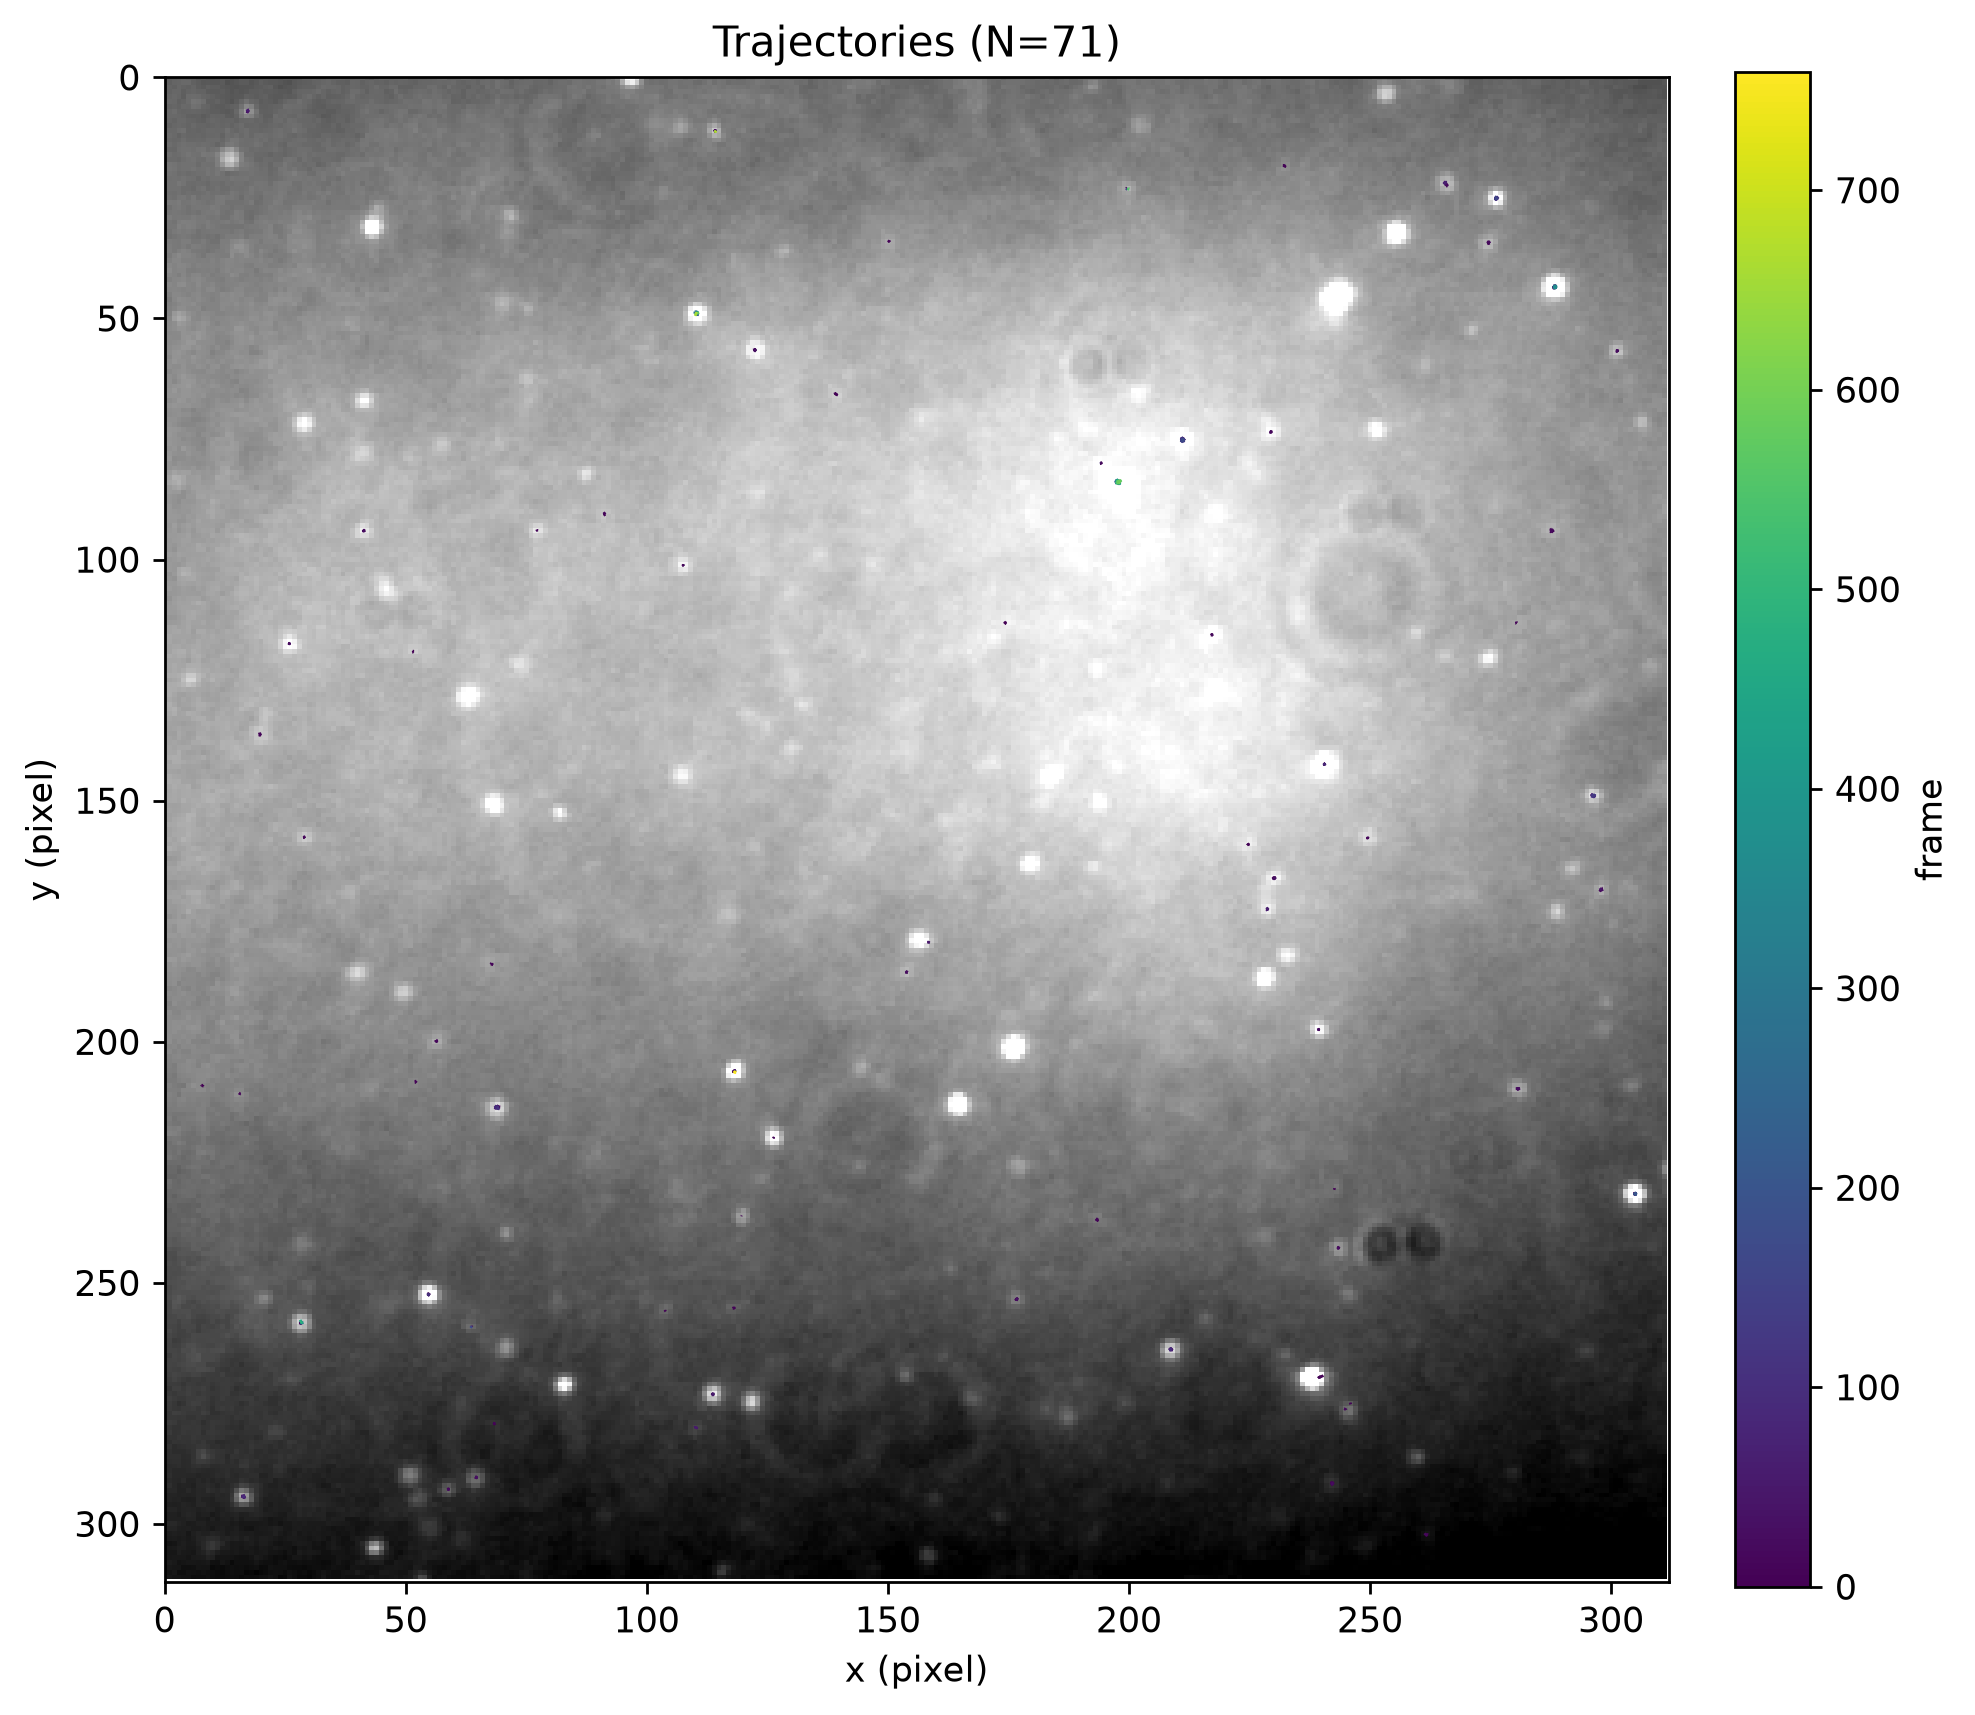

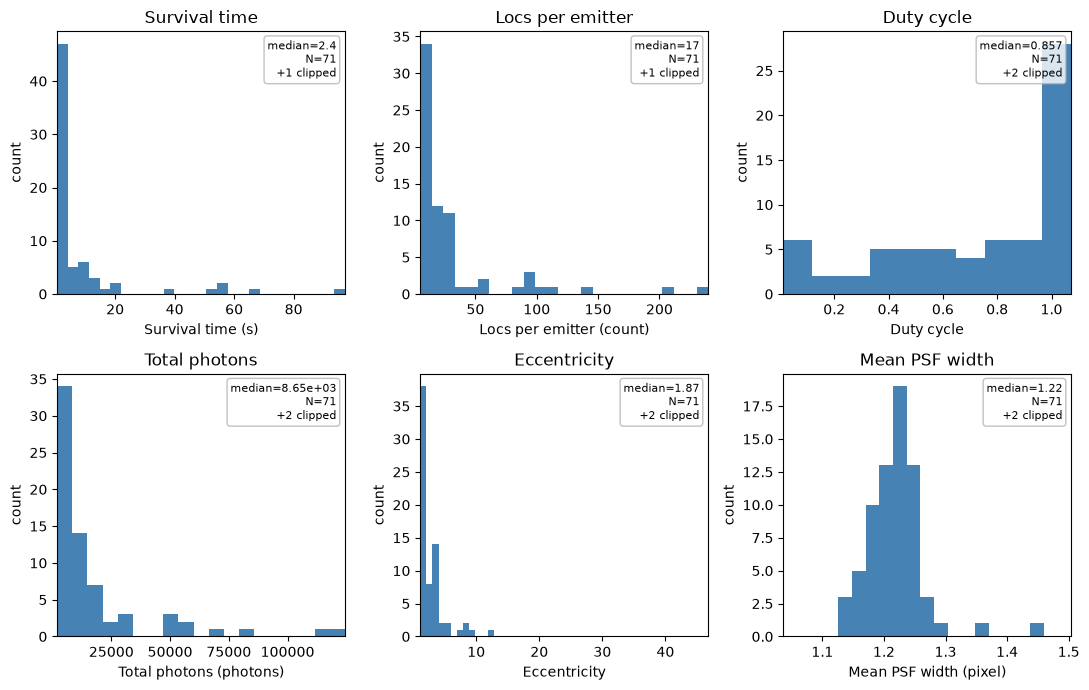

In [21]:
from smlm.viz import plot_trajectories, plot_bleaching_summary, plot_emitter_stats
plot_trajectories(corr_image.data, emitters, linewidth=0.7, frame_idx=np.arange(0, 500), dpi=250)
plot_emitter_stats(stats)

## Trace Extraction — 逐字段填充

`TraceFillPipeline` 每分子裁一份 ROI，再按顺序交给若干"填充阶段"。每个阶段只写自己
声明的字段，所以换方法就是换那个列表：

| 阶段 | 写入的字段 |
|---|---|
| `ApertureRaw` | `raw`（加权积分）、`sigma` / `radius` / `mode` / `sw` / `sw2` / `area` |
| `AnnulusRing` | `bg`（环内逐帧 sigma-clip 中位数，ADU/px）、`bg_std`、`n_bg_pixels`、`neighbours` |
| `IntensityFromRawBg` | `intensity = raw − bg·sw/sw2`、`bg_flux` |

`snr` 不在这里算 —— 它按需事后追加，见下面的单元。
约定不变：`fill_traces[i]` 对应 `emitters[i]`。
**两个中心表分开给：**

- `centers_for_raw` —— 要提信号的分子（结果与它一一对齐）
- `centers_for_bg` —— 背景环要**挖掉**的分子中心，默认同上；高密度或多通道时传一张更完整的表，
  否则邻居的 PSF 会漏进环里把 `bg` 抬高

**σ 必须显式给**（`sigma=`），不再从 `locs` 逐分子估计 —— 高密度时"中心 2px 内的定位点"
会混进邻居，σ 偏大 → 半径偏大 → 环里收到更多邻居光，同时 matched 权重核也被拉宽。
下一个单元用 λ/NA 算一个统一 σ。

In [22]:
# ---- PSF σ: 用**拟合宽度**的中位 (与 smTest_dual 同一口径), 不用 λ/NA 的理论值 ----
# 理论值假设理想、恰好在焦面的 PSF; 实测常比它宽 40~50% (像差/离焦/波前)。σ 决定
# 孔径半径 ceil(k_sigma·σ) (被 ApertureRaw 夹在 [2,7] px) 与匹配滤波幅度, 偏小会让
# intensity 整体被压低, 后面的 SNR / 阈值门限全跟着失真。
from smlm.localize import psf_sigma

WAVELEN_NM, NA = 640.0, 1.4                      # 只用来打印理论值做对照
SIGMA_THEORY = 0.2165 * WAVELEN_NM / NA / float(pixel_size)
SIGMA_PX = psf_sigma(corr_locs)                  # 拟合宽度中位 (剔离群)
R_SIGNAL = int(np.ceil(2.0 * SIGMA_PX))

print(f'σ(拟合) = {SIGMA_PX:.2f} px    理论 {SIGMA_THEORY:.2f} px    '
      f'比值 {SIGMA_PX / SIGMA_THEORY:.2f}')
print(f'孔径半径: k_sigma=2 -> {R_SIGNAL} px'
      f'{"   (超出 [2,7], 会被夹住)" if not 2 <= R_SIGNAL <= 7 else ""}')
if SIGMA_PX > 1.25 * SIGMA_THEORY:
    print('  [!] 拟合明显宽于理论: 检查是否离焦 (或换一个更宽的 λ/NA 近似)')

σ(拟合) = 1.18 px    理论 0.93 px    比值 1.27
孔径半径: k_sigma=2 -> 3 px
  [!] 拟合明显宽于理论: 检查是否离焦 (或换一个更宽的 λ/NA 近似)


In [23]:
import smlm.trace as tr

# 与 emitters 一一对应: 要提信号的那批分子
centers_for_raw = np.array([[e.centroid[1], e.centroid[0]] for e in emitters])

pipe = tr.TraceFillPipeline(
    corr_image.data, centers_for_raw,
    sigma=SIGMA_PX,               # 拟合宽度中位 (见上一格), 全体统一
    # centers_for_bg=None,        # 默认同 centers_for_raw; 高密度时换成更完整的分子表
    n_frames=corr_image.n_frames,
    tag='single',
)
fill_traces = pipe.run(
    [tr.ApertureRaw(k_sigma=2.0),              # 信号: raw
     tr.AnnulusRing(gap=2, width=4,            # 背景: 分子周围的环
                    excl_radius=2),
     tr.IntensityFromRawBg()],                 # intensity = raw - bg
    verbose=True,
)

print(len(fill_traces), 'traces')
print('fields:', sorted(fill_traces[0]))
fill_traces[0]

  [single] 71 条 trace, 阶段: ApertureRaw -> AnnulusRing -> IntensityFromRawBg
  [single]   ApertureRaw: matched, r=2σ, [2, 7] px
  [single]   AnnulusRing: ring +2..+6 px, excl 2, clip 3x3
  [single]   IntensityFromRawBg: intensity = raw - bg*sw/sw2
  [single]   半径 3~3 px (中位 3), σ 中位 1.18 px
  [single]   背景中心 71 个(自己), 环像素中位 175, 邻居中位 0
71 traces
fields: ['area', 'bg', 'bg_flux', 'bg_std', 'channel', 'emitter_id', 'frames', 'intensity', 'mode', 'n_bg_pixels', 'neighbours', 'radius', 'raw', 'sigma', 'sw', 'sw2', 'x', 'y']


Trace(emitter_id=0, frames=array(2000,), x=239.71544150152357, y=269.56447002230345, channel='single', sigma=1.179090068431531, radius=3, mode='matched', sw=0.9854991589629346, sw2=0.057228108976924784, area=37.0, raw=array(2000,), bg=array(2000,), bg_std=array(2000,), n_bg_pixels=164, neighbours=2, bg_flux=array(2000,), intensity=array(2000,))

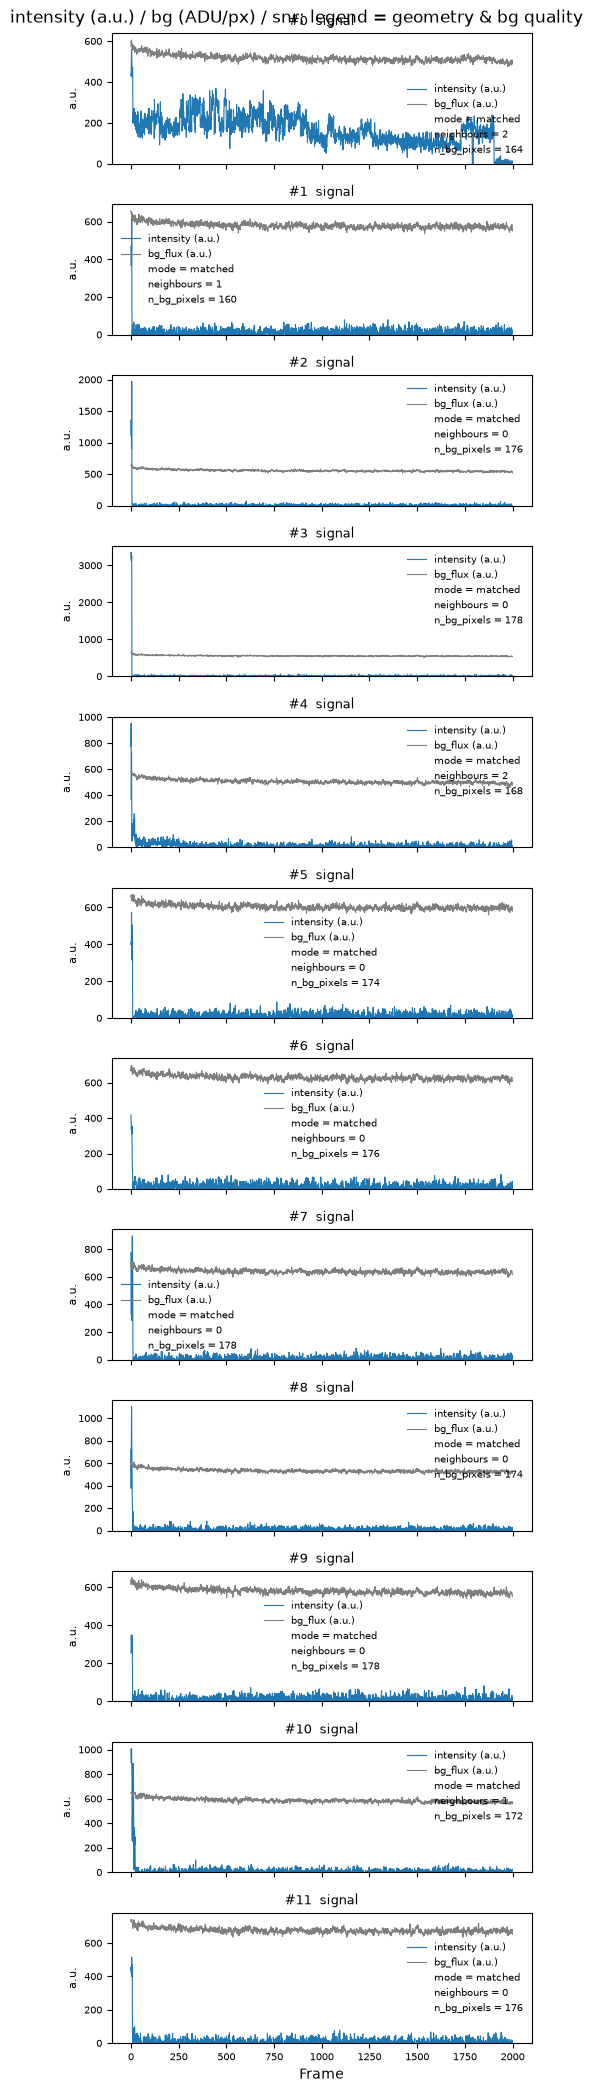

In [27]:
import matplotlib.pyplot as plt

fig = tr.plot_trace_fields(
    fill_traces, indices=range(12),
    groups={'signal': dict(fields=('intensity','bg_flux'), color=('tab:blue','tab:grey')),
           },
    scalars=('mode', 'neighbours', 'n_bg_pixels'),
    title='intensity (a.u.) / bg (ADU/px) / snr; legend = geometry & bg quality')
plt.show()

## Trace 状态判定（阈值法）

`ThresholdStates` 只看 `intensity`：

- 高于 `high` 算 **ON**（阈值由你给定，不做自适应）；
- 最后一个 ON 之后**连续 OFF 至少 `bleach_frames` 帧**，才认为**已漂白** ——
  漂白是时间判定，不是亮度判定。

`state` 存的是**亮度等级**，不是状态码：`0` = 最暗（OFF），更大的数 = 更亮的等级。
阈值法只产生 0/1 两个等级，变点法可以产生 0..k-1。漂白不在 `state` 里，看
`bleach_frame`（-1 = 未漂白）和 `alive`（False 段 = 已漂白）。

其余字段：`fit`（每个等级的拟合亮度）、`n_states`（等级数）、`n_on`（闪烁次数）、
`n_switches`（二值 ON/OFF 切换次数）、`n_cp`（等级切换次数）、`on_frames`、`on_fraction`。

In [29]:
STATE_HIGH = 100.0        # ON 阈值 (与 intensity 同单位), 自己调
BLEACH_FRAMES = 1000        # 连续 OFF 多少帧算漂白 (约占记录的 1/4)

fill_traces = pipe.add_fields(
    fill_traces,
    [tr.ThresholdStates(high=STATE_HIGH, bleach_frames=BLEACH_FRAMES,
                        min_on=1, min_off=1)],
    verbose=True,
)

tb = tr.to_table(fill_traces)
print('闪烁次数 n_on : 中位', int(np.median(tb['n_on'])),
      '范围', int(tb['n_on'].min()), '-', int(tb['n_on'].max()))
print('切换次数      : 中位', int(np.median(tb['n_switches'])))
print('ON 占比       : 中位', round(float(np.median(tb['on_fraction'])), 3))
print('已漂白        :', int((tb['bleach_frame'] >= 0).sum()), '/', len(fill_traces))


  [single] 追加字段: ThresholdStates
闪烁次数 n_on : 中位 2 范围 1 - 226
切换次数      : 中位 2
ON 占比       : 中位 0.875
已漂白        : 57 / 71


C:\Users\Jerry Ling\AppData\Local\Temp\ipykernel_4436\2571874850.py:4: UserWarning: ThresholdStates 覆盖已存在的字段 ['state', 'fit', 'n_states', 'bleach_frame', 'alive', 'n_on', 'n_switches', 'n_cp', 'on_frames', 'on_fraction']; 若前面的阶段已经用旧值算过结果, 那些结果不会自动重算
  fill_traces = pipe.add_fields(


### 按状态质量筛 trace

`select_traces` 按字段范围筛，返回**索引列表**；位置、背景等其它字段都还在原来的 trace 里。


In [31]:
KEEP = tr.select_traces(
    fill_traces,
    n_on=(0, 80),                 # 闪烁 1~8 次
    n_switches=(3, 80),
         # 必须漂白
)
print(len(KEEP), 'traces 通过;', len(fill_traces) - len(KEEP), '条被筛掉')
KEEP[:20]


30 traces 通过; 41 条被筛掉


[4, 10, 14, 18, 23, 27, 29, 33, 34, 36, 37, 39, 40, 43, 44, 45, 47, 48, 49, 51]

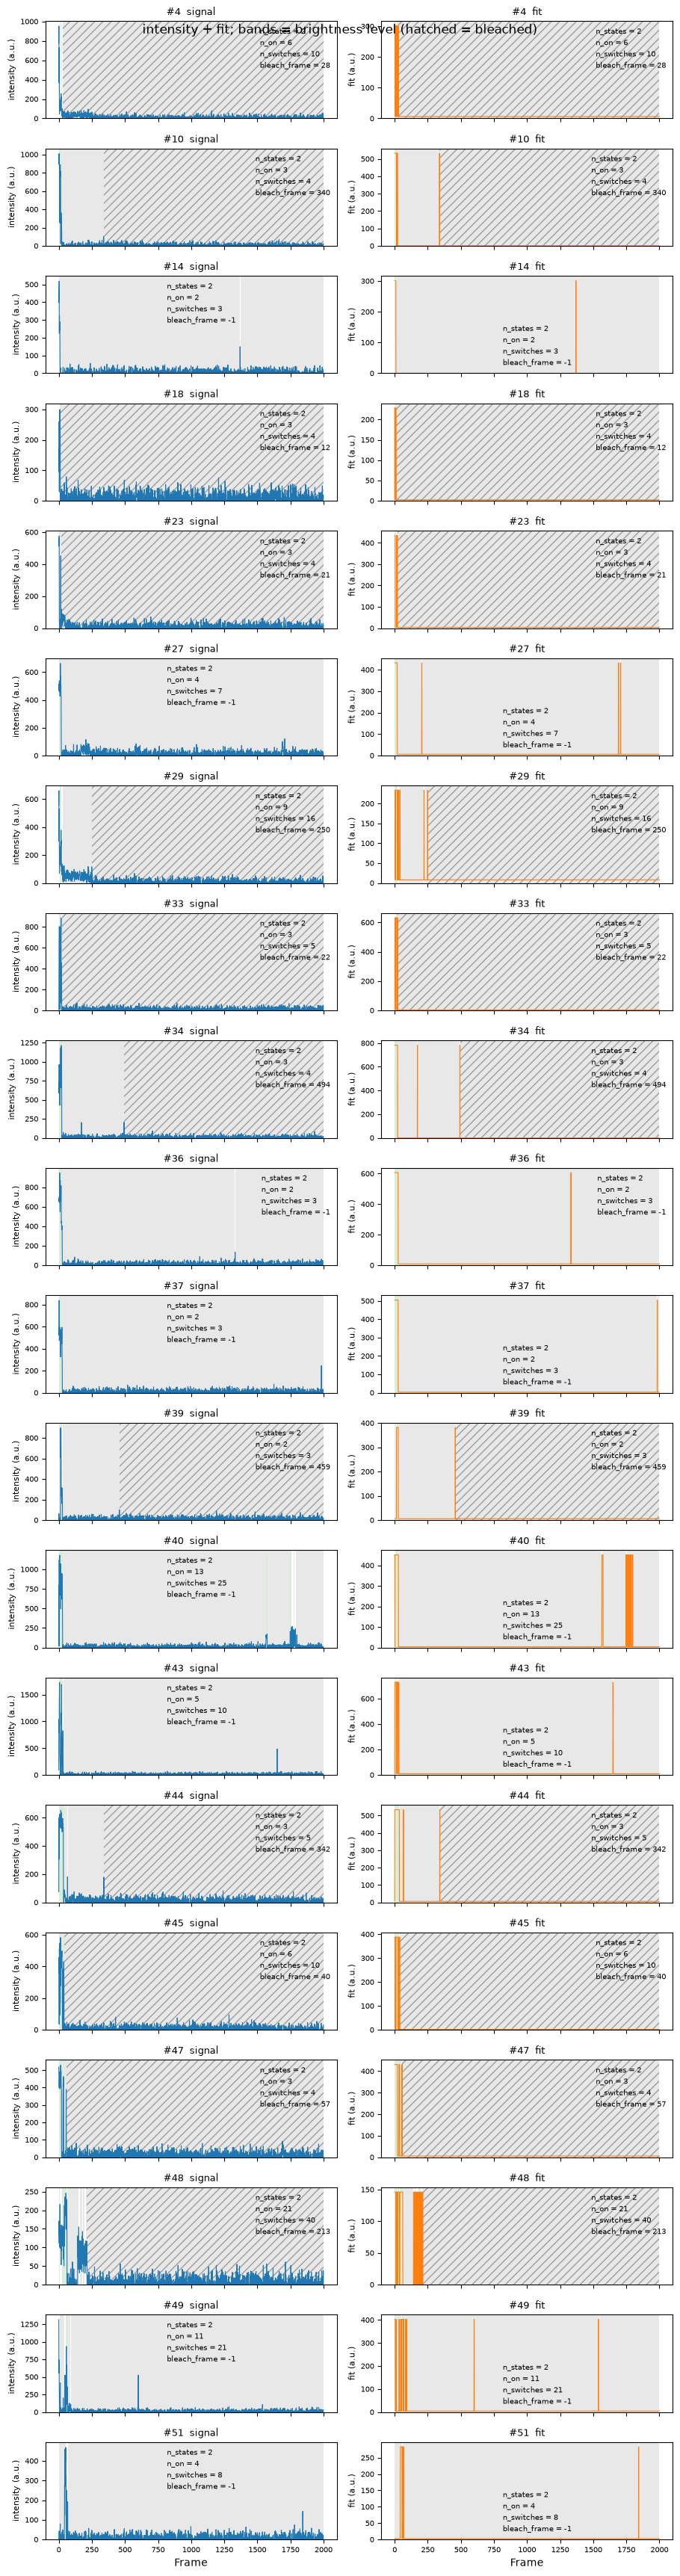

In [32]:
if not KEEP:
    print('没有 trace 通过筛选, 放宽条件或调整阈值')
else:
    fig = tr.plot_trace_fields(
        fill_traces, indices=KEEP[:20],
        groups={'signal': dict(fields=('intensity',), color='tab:blue'),
                'fit': dict(fields=('fit',), color='tab:orange')},
        scalars=('n_states', 'n_on', 'n_switches', 'bleach_frame'),
        bands='state',
        title='intensity + fit; bands = brightness level (hatched = bleached)')
    plt.show()

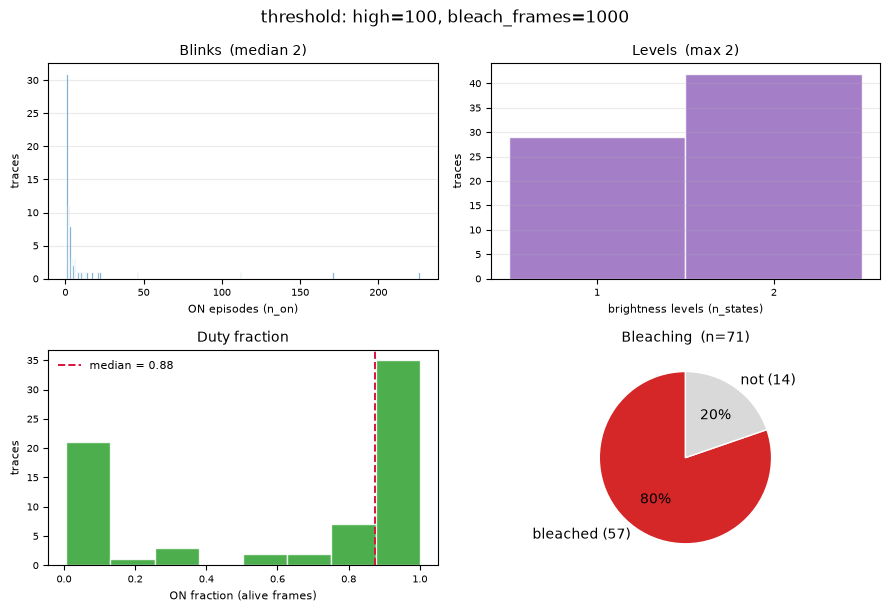

In [33]:
tr.plot_state_summary(
    fill_traces,
    title=f'threshold: high={STATE_HIGH:g}, bleach_frames={BLEACH_FRAMES}')
plt.show()

### 单个分子：先看，再决定存不存（批量）

`traces[i]` 与 `emitters[i]` 一一对应，所以 trace 索引**直接**就是 emitter 索引。

`preview_emitters(...)` 一次渲染 **多个**窗口，每个都和 `save_movie` 完全同款：
- 窗口以该 emitter 定位的**中位数**为中心，尺寸 `(2*half+1)^2`
- 右侧是这条 trace 的 `intensity` 曲线（`save_movie` 的面板只画这一个字段），随视频帧同步推进
- `×` 是该分子自己的定位点（`corr_locs[emitters[i].loc_idx]`）

`IDX` 就是"要看 / 要存"的名单，改它就够了。看完满意，去下一个单元把 `SAVE` 打开才会落盘。

In [ ]:
from smlm.viz import preview_emitters

IDX = list(KEEP[:1])        # 名单: 也可以写 IDX = KEEP[:12] 或 IDX = [0, 3, 7]

preview_emitters(
    corr_image, fill_traces, emitters, corr_locs,
    indices=IDX, half=12, frames=slice(0, 600),
    ncols=2, width=420,
    exposure_time=raw.exposure_time, speed=5,
)

In [ ]:
import os
from smlm.viz import save_emitters

SAVE = False                             # True 就批量写盘, 文件名见 pattern
HALF, FRAMES = 12, slice(0, 600)

if SAVE:
    out_dir = os.path.dirname(src)
    tag = os.path.splitext(os.path.basename(src))[0]
    paths = save_emitters(
        corr_image, fill_traces, emitters, corr_locs,
        indices=IDX, out_dir=out_dir,
        pattern=f"{tag}_em{{idx:03d}}.mp4",
        half=HALF, frames=FRAMES,
        exposure_time=raw.exposure_time, speed=5, clim=(15, 85),
    )
    print(f"saved {len(paths)} movies -> {out_dir}")
else:
    print(f"preview only; set SAVE = True to write {len(IDX)} movies")

## 另一种状态判定：变点法

阈值法需要你给一个 `high`；变点法（`ChangepointStates`）不需要 —— 它自己找亮度相近的段，
再把段聚成**亮度等级**，等级数由数据定。

两条路线的输出字段**完全一样**（`state` / `fit` / `bleach_frame` / `alive` / `n_on` /
`n_switches` / `n_cp` / `n_states`），因为漂白判定和计数都走同一个
`summarize_states`。所以上面的 `select_traces` / `plot_trace_fields` / 视频预览全都通用。

`n_states > 2` 通常意味着一个窗口里有两个分子，用 `n_states=(1, 2)` 筛掉。

In [ ]:
# 复制一份, 剥掉阈值法的状态字段 (否则会被警告"覆盖")
DROP = ('state', 'fit', 'n_states', 'bleach_frame', 'alive',
        'n_on', 'n_switches', 'n_cp', 'on_frames', 'on_fraction')
cp_traces = [tr.Trace({k: v for k, v in t.items() if k not in DROP})
             for t in fill_traces]

CP = tr.ChangepointStates(
    bleach_frames=500,      # 与阈值法同名同义: 末尾连续 OFF >= 500 帧 = 漂白
    penalty=3.0,            # 越大 -> 切点越少 -> 等级越少
    min_seg=5,              # 最短段长, 抑制单帧 glitch
    merge_thr=2.0,          # 段中位数差 < 2σ 就算同一等级
    vst=None,               # 暗分子 (亮/暗 < 5x) 可以试 'anscombe'
)
cp_traces = pipe.add_fields(cp_traces, [CP], verbose=True)

In [ ]:
if not KEEP:
    print('没有 trace 通过筛选, 放宽条件或调整阈值')
else:
    fig = tr.plot_trace_fields(
        cp_traces, indices=KEEP[:12],
        groups={'signal': dict(fields=('intensity',), color='tab:blue'),
                'fit': dict(fields=('fit',), color='tab:orange')},
        scalars=('n_states', 'n_cp', 'n_on', 'bleach_frame'),
        bands='state',
        title='changepoint: intensity + fit; bands = brightness level')
    plt.show()

In [ ]:
tr.plot_state_summary(cp_traces, title='changepoint')
plt.show()